# Netflix Customer Churn - Model Training and Evaluation
**Notebook outline:**
1. Setup and loading processed data
2. Logistic Regression
3. Decision Tree (3 levels)
4. Decision Tree (5 levels)
5. Model comparision and selection

## 1. Setup and loading processed data

In [141]:
from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, precision_score, recall_score, f1_score

In [142]:
random_state = 42
processed_data_path = Path("../data/processed")
models_path = Path("../models")

In [143]:
X_train = pd.read_csv(processed_data_path / "X_train.csv")
X_test = pd.read_csv(processed_data_path / "X_test.csv")
y_train = pd.read_csv(processed_data_path / "y_train.csv").values.ravel()
y_test = pd.read_csv(processed_data_path / "y_test.csv").values.ravel()

> **Check:** `X_train`, `X_test`, `y_train` and `y_test` are loaded from `../data/processed`. The target arrays are flattened with `.ravel()` so they can be passed directly to scikit-learn estimators. The test set remains separate and is used only for evaluation.

## 2. Logistic Regression

In [144]:
model = LogisticRegression(max_iter=1000, random_state=random_state)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_prob = model.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, y_pred_prob):.4f}")

print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9200
ROC-AUC:  0.9784

Confusion matrix:
 [[457  40]
 [ 40 463]]

Classification report:
               precision    recall  f1-score   support

           0       0.92      0.92      0.92       497
           1       0.92      0.92      0.92       503

    accuracy                           0.92      1000
   macro avg       0.92      0.92      0.92      1000
weighted avg       0.92      0.92      0.92      1000



> **Check:** the model reaches **0.9200 Accuracy** and **0.9784 ROC-AUC** on the held-out test set. The confusion matrix contains 457 correctly predicted non-churners and 463 correctly predicted churners, with 40 false positives and 40 false negatives. Precision, recall and F1-score are approximately 0.92 for both classes, indicating balanced classification performance at the default decision threshold.

In [145]:
coef_df = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": model.coef_[0],
}).sort_values(by="coefficient", ascending=False)
print(coef_df)

                           feature  coefficient
9                bin__inactive_30d     4.110572
1             num__last_login_days     2.751389
11              bin__risky_payment     1.306540
5       cat__payment_method_Crypto     0.697766
7    cat__payment_method_Gift Card     0.608774
8       cat__payment_method_PayPal    -0.037324
6   cat__payment_method_Debit Card    -0.160162
3          num__number_of_profiles    -0.635828
10             bin__profiles_4plus    -2.147113
2                 num__monthly_fee    -2.540200
0                 num__watch_hours    -2.890154
4             num__log_watch_hours    -3.134646


> **Coefficients:** the Logistic Regression coefficients show the direction and strength of each feature's association with the predicted churn log-odds, holding the other input features constant. `inactive_30d` (4.11), `last_login_days` (2.75) and `risky_payment` (1.31) have the largest positive coefficients. `log_watch_hours` (-3.13), `watch_hours` (-2.89), `monthly_fee` (-2.54) and `profiles_4plus` (-2.15) have the largest negative coefficients. These are model associations, not causal effects.

In [146]:
models_path.mkdir(parents=True, exist_ok=True)
joblib.dump(model, models_path / "logistic_regression.joblib")

['..\\models\\logistic_regression.joblib']

## 3. Decision Tree (3 levels)

In [147]:
tree_model = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=20,
    random_state=random_state,
)
tree_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

In [148]:
y_pred1 = tree_model.predict(X_test)
y_pred_prob1 = tree_model.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred1):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, y_pred_prob1):.4f}")

print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred1))
print("\nClassification report:\n", classification_report(y_test, y_pred1))

Accuracy: 0.9080
ROC-AUC:  0.9397

Confusion matrix:
 [[425  72]
 [ 20 483]]

Classification report:
               precision    recall  f1-score   support

           0       0.96      0.86      0.90       497
           1       0.87      0.96      0.91       503

    accuracy                           0.91      1000
   macro avg       0.91      0.91      0.91      1000
weighted avg       0.91      0.91      0.91      1000



> **Check:** the 3-level tree obtains **0.9080 Accuracy** and **0.9397 ROC-AUC** on the test set. Its confusion matrix shows 483 correctly identified churners and 20 false negatives, alongside 425 correctly identified non-churners and 72 false positives. For the churn class (`1`), Recall is **0.9602**, while Precision is **0.8703**. This means the model identifies most churners, but it also flags a larger number of customers who do not churn.

In [149]:
coef_df1 = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": tree_model.feature_importances_,
}).sort_values(by="coefficient", ascending=False)
print(coef_df1)

                           feature  coefficient
4             num__log_watch_hours     0.361031
9                bin__inactive_30d     0.321557
0                 num__watch_hours     0.203870
1             num__last_login_days     0.090863
2                 num__monthly_fee     0.022679
3          num__number_of_profiles     0.000000
6   cat__payment_method_Debit Card     0.000000
5       cat__payment_method_Crypto     0.000000
7    cat__payment_method_Gift Card     0.000000
8       cat__payment_method_PayPal     0.000000
10             bin__profiles_4plus     0.000000
11              bin__risky_payment     0.000000


> **Coefficient:** `feature_importances_` reports the relative contribution of features to the tree's splits; unlike Logistic Regression coefficients, these values have no positive/negative direction. The strongest features are `log_watch_hours` (0.361), `inactive_30d` (0.322), `watch_hours` (0.204) and `last_login_days` (0.091). The remaining features have very small or zero importance in this fitted tree, meaning they were not used for its effective splits.

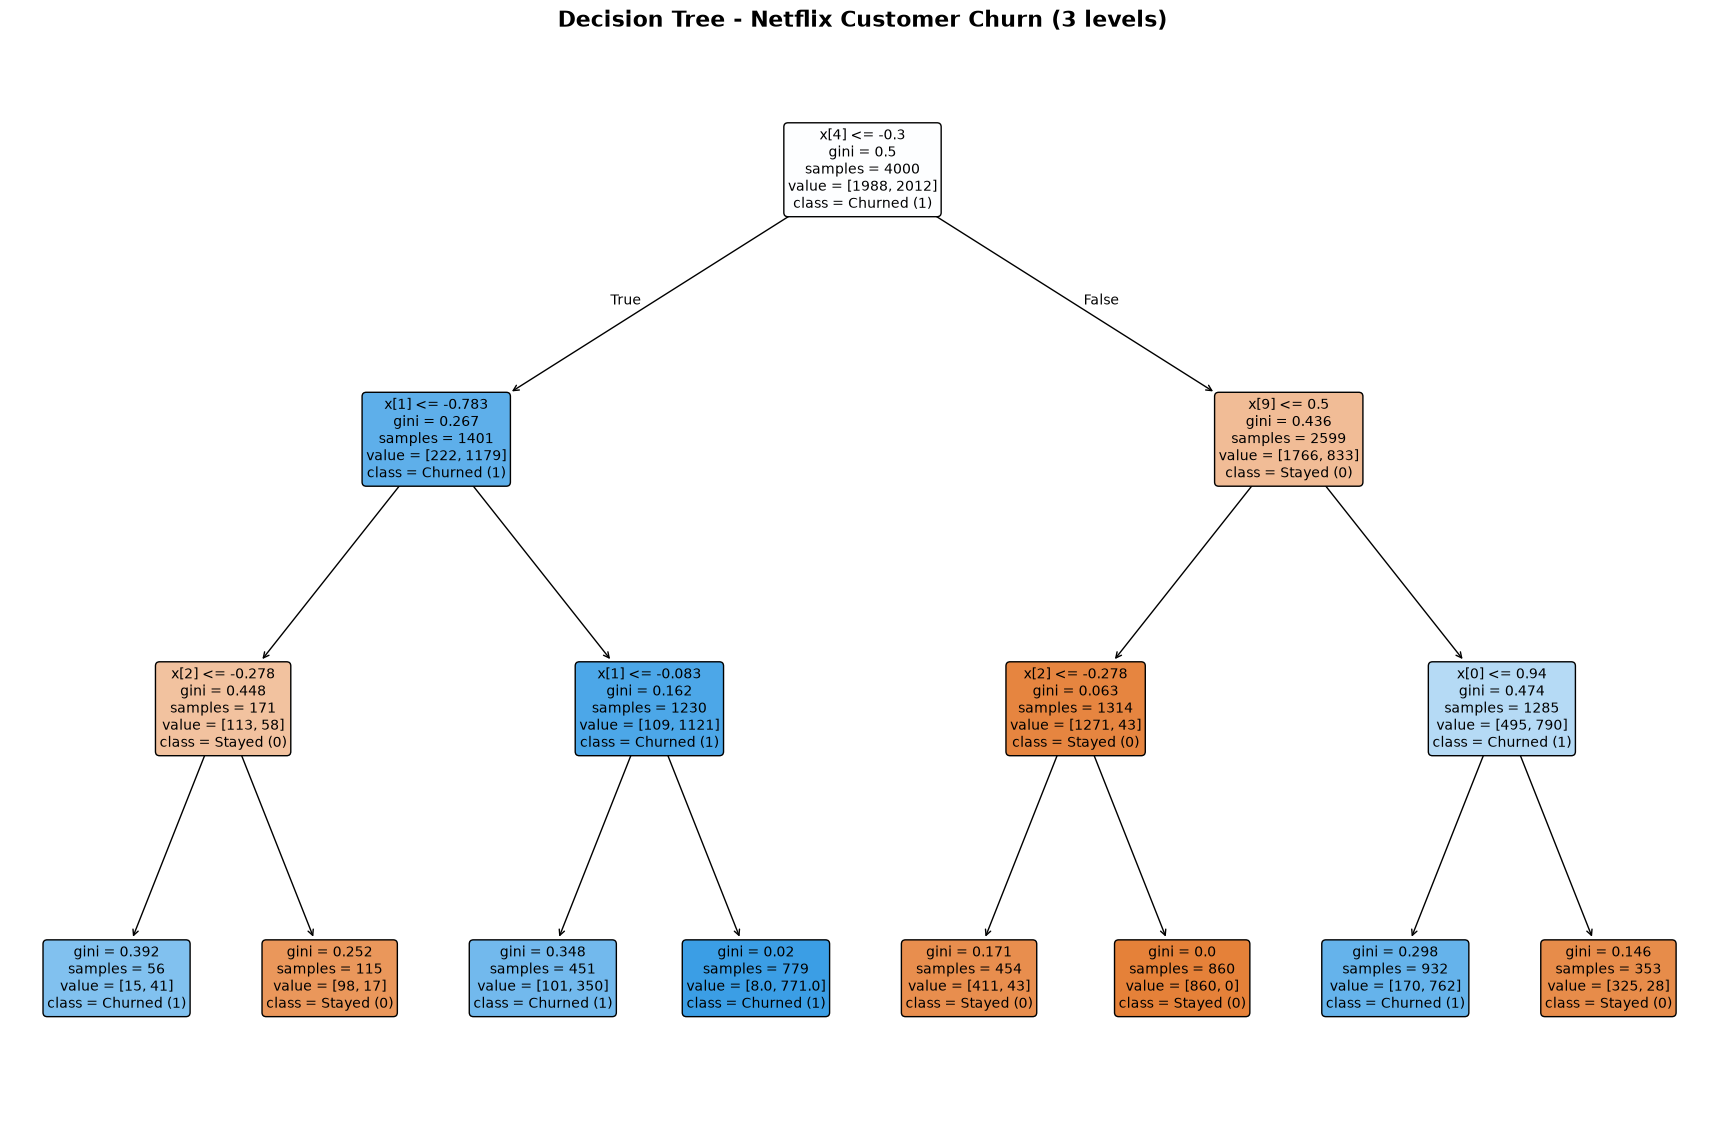

In [150]:
plt.figure(figsize=(22, 14))
plot_tree(
    tree_model,
    class_names=["Stayed (0)", "Churned (1)"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=10,
)
plt.title("Decision Tree - Netflix Customer Churn (3 levels)", fontsize=16, fontweight="bold")

plt.savefig('../reports/charts/21_decision_tree_churn(3 levels).png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [151]:
models_path.mkdir(parents=True, exist_ok=True)
joblib.dump(tree_model, models_path / "decision_tree_3_depth.joblib")

['..\\models\\decision_tree_3_depth.joblib']

## 4. Decision Tree (5 levels)

In [152]:
tree_model1 = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=20,
    random_state=random_state,
)
tree_model1.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

In [153]:
y_pred2 = tree_model1.predict(X_test)
y_pred_prob2 = tree_model1.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred2):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, y_pred_prob2):.4f}")

print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred2))
print("\nClassification report:\n", classification_report(y_test, y_pred2))

Accuracy: 0.9340
ROC-AUC:  0.9864

Confusion matrix:
 [[478  19]
 [ 47 456]]

Classification report:
               precision    recall  f1-score   support

           0       0.91      0.96      0.94       497
           1       0.96      0.91      0.93       503

    accuracy                           0.93      1000
   macro avg       0.94      0.93      0.93      1000
weighted avg       0.94      0.93      0.93      1000



> **Check:** the 5-level tree achieves **0.9340 Accuracy** and **0.9864 ROC-AUC**, the strongest values among the three models in this notebook. Its confusion matrix contains 456 true positives, 478 true negatives, 19 false positives and 47 false negatives. For churn (`1`), Precision is **0.9600** and Recall is **0.9066**. Compared with the shallower tree, this model makes fewer false-positive predictions but misses more actual churners.

In [154]:
coef_df2 = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": tree_model1.feature_importances_,
}).sort_values(by="coefficient", ascending=False)
print(coef_df2)

                           feature  coefficient
4             num__log_watch_hours     0.302926
9                bin__inactive_30d     0.260666
0                 num__watch_hours     0.165319
3          num__number_of_profiles     0.089525
1             num__last_login_days     0.079250
11              bin__risky_payment     0.078727
2                 num__monthly_fee     0.022072
10             bin__profiles_4plus     0.001516
7    cat__payment_method_Gift Card     0.000000
6   cat__payment_method_Debit Card     0.000000
5       cat__payment_method_Crypto     0.000000
8       cat__payment_method_PayPal     0.000000


> **Coefficient:** the most influential features are `log_watch_hours` (0.303), `inactive_30d` (0.261), `watch_hours` (0.165), `number_of_profiles` (0.090), `last_login_days` (0.079) and `risky_payment` (0.079). `monthly_fee` contributes less (0.022), while `profiles_4plus` has very small importance (0.002) and the encoded payment-method indicators have zero importance in this fitted tree. These are relative split importances, not signed effects.

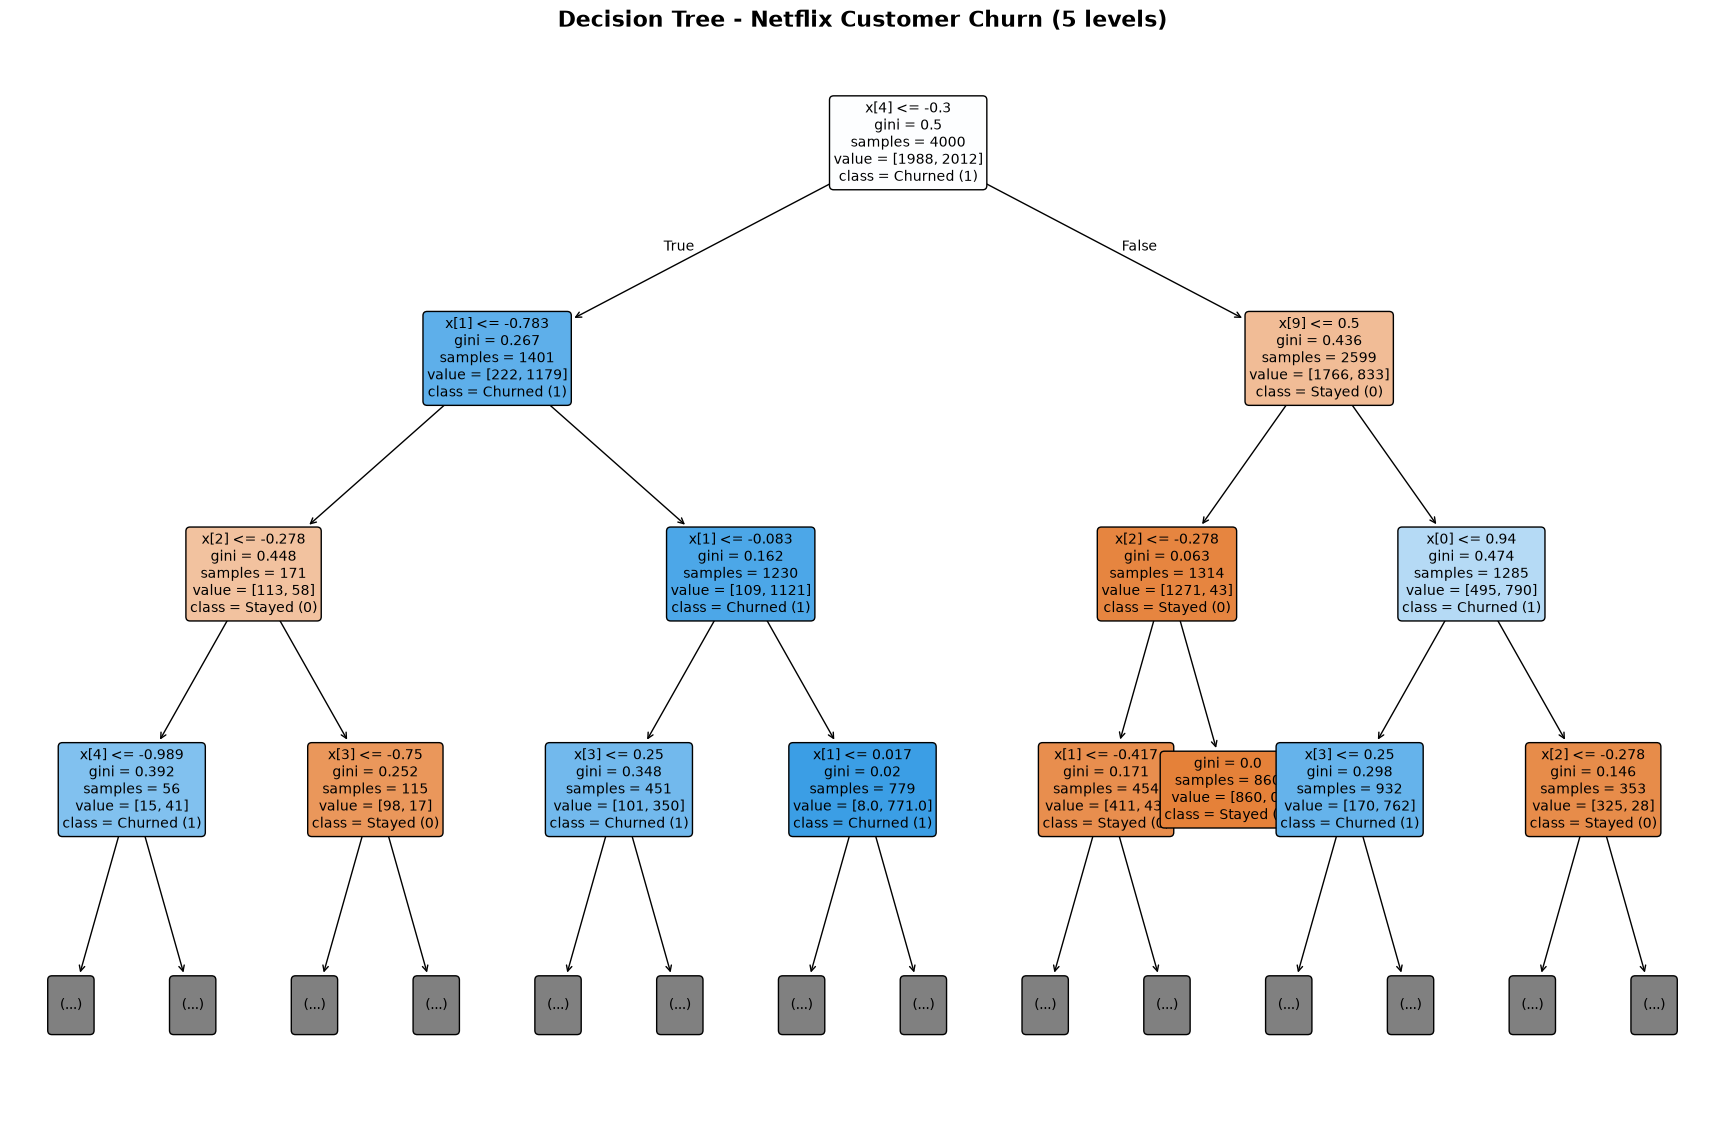

In [155]:
plt.figure(figsize=(22, 14))
plot_tree(
    tree_model1,
    class_names=["Stayed (0)", "Churned (1)"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=10,
)
plt.title("Decision Tree - Netflix Customer Churn (5 levels)", fontsize=16, fontweight="bold")

plt.savefig('../reports/charts/22_decision_tree_churn(5 levels).png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [156]:
models_path.mkdir(parents=True, exist_ok=True)
joblib.dump(tree_model1, models_path / "decision_tree_5_depth.joblib")

['..\\models\\decision_tree_5_depth.joblib']

## 5. Model comparision and selection

In [157]:
models = {
    "Logistic Regression": model,
    "Decision Tree (depth=3)": tree_model,
    "Decision Tree (depth=5)": tree_model1
}

In [158]:
results = []
for name, clf in models.items():
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-score": round(f1_score(y_test, y_pred), 4),
    })

comparison_df = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False)
display(comparison_df)

,Model,Accuracy,ROC-AUC,Precision,Recall,F1-score
2,Decision Tree (depth=5),0.934,0.9864,0.9600,0.9066,0.9325
0,Logistic Regression,0.920,0.9784,0.9205,0.9205,0.9205
1,Decision Tree (depth=3),0.908,0.9397,0.8703,0.9602,0.9130


> **Takeaway:** `Decision Tree (depth=5)` performs best overall on this test split, with the highest Accuracy (0.9340), ROC-AUC (0.9864), Precision (0.9600) and F1-score (0.9325). `Decision Tree (depth=3)` has the highest churn Recall (0.9602), so it detects more of the actual churners but generates more false positives. Logistic Regression provides a balanced result, with Precision and Recall both around 0.9205. The preferred model therefore depends on the business cost of the two error types: missing a customer who will churn (false negative) versus unnecessarily targeting a customer who will stay (false positive).